# Lecture 8: Econometrics in Python

- Lectures 1-5 covered the Python language. In Lecture 6 we worked with data in NumPy and pandas, and in Lecture 7 we plotted it.

- From here on, the focus is on running standard econometric methods in Python.

- This lecture is about **inference**: estimating relationships and testing whether they are statistically significant (coefficients, standard errors, hypothesis tests).

- Lecture 9 is about **prediction**: building models that forecast well out of sample.

## What We'll Cover

- **Ch 15 (Statistical Foundations):** descriptive statistics, correlation, and hypothesis tests with `scipy.stats`.
- **Ch 16 (Linear Regression):** OLS, robust/clustered/HAC standard errors, and diagnostics with `statsmodels`.
- **Ch 17 (Panel Data & IV):** fixed effects, instrumental variables, and Fama-MacBeth with `linearmodels`.
- **Ch 18 (Volatility Modeling):** ARCH/GARCH with `arch`.

- Most examples use the Fama-French 5 factors and the 10 industry portfolios from Ken French's data library, both widely used in empirical asset pricing.

## Setup: Installing and Importing Libraries

- `statsmodels`, `scipy`, and `numpy`/`pandas` come pre-installed in Colab.
- `linearmodels` (panel/IV) and `arch` (GARCH) are not, so we install them.

In [ ]:
!pip install -q linearmodels arch

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

## Loading Our Data

- We need two datasets from Ken French's library: the 5 factors and the 10 industry portfolios.

- We write a small helper function, `load_french()`, that loads any monthly French dataset (recall functions from Lecture 4). It tries pandas-datareader first and falls back to a direct download.

In [ ]:
import io, zipfile, urllib.request

def load_french(dataset, colnames, start='1990-01-01', end='2023-12-31'):
    """Load a monthly dataset from Ken French's data library.
    Tries pandas-datareader first, then falls back to a direct download."""
    try:
        import pandas_datareader.data as web
        data = web.DataReader(dataset, 'famafrench', start=start, end=end)[0]
        data.index = data.index.to_timestamp()
        return data
    except Exception as e:
        print(f"datareader failed ({type(e).__name__}); using direct download for {dataset}.")
        url = (f"https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/"
               f"ftp/{dataset}_CSV.zip")
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as r:
            raw = zipfile.ZipFile(io.BytesIO(r.read()))
            text = raw.open(raw.namelist()[0]).read().decode('latin1')
        lines = text.splitlines()
        s = next(i for i, ln in enumerate(lines)
                 if len(ln.strip()) >= 6 and ln.strip()[:6].isdigit())
        e_ = next((i for i in range(s, len(lines))
                   if not (len(lines[i].strip()) >= 6 and lines[i].strip()[:6].isdigit())),
                  len(lines))
        block = "\n".join(lines[s:e_])
        data = pd.read_csv(io.StringIO(block), header=None,
                           names=['Date'] + colnames, index_col='Date')
        data.index = pd.to_datetime(data.index, format='%Y%m')
        return data.replace(-99.99, np.nan)

### Load the Five Factors

- Columns are `Mkt-RF`, `SMB`, `HML`, `RMW`, `CMA`, and the risk-free rate `RF`.

In [ ]:
factor_cols = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']
factors = load_french('F-F_Research_Data_5_Factors_2x3', factor_cols)
factors.head()

,Mkt-RF,SMB,HML,RMW,CMA,RF
Date,,,,,,
1990-01-01,-7.80,-1.21,0.83,-1.12,1.40,0.57
1990-02-01,1.11,1.15,0.65,-0.04,-0.61,0.57
1990-03-01,1.83,1.59,-2.90,1.99,-0.94,0.64
1990-04-01,-3.36,-0.35,-2.57,1.78,-1.00,0.69
1990-05-01,8.44,-2.41,-3.89,1.68,-1.63,0.68


### Rename Columns for Formula Compatibility

- `statsmodels` formulas treat a hyphen as a minus sign, so `Mkt-RF` would be parsed as `Mkt` minus `RF`.

- We rename `Mkt-RF` to `Mkt_RF` to avoid this.

In [ ]:
factors = factors.rename(columns={'Mkt-RF': 'Mkt_RF'})
factors.columns

Index(['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF'], dtype='object')

### Load the 10 Industry Portfolios

- These are monthly value-weighted returns for 10 broad industries.

In [ ]:
industry_cols = ['NoDur', 'Durbl', 'Manuf', 'Enrgy', 'HiTec',
                 'Telcm', 'Shops', 'Hlth', 'Utils', 'Other']
industries = load_french('10_Industry_Portfolios', industry_cols)
industries.head()

,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
Date,,,,,,,,,,
1990-01-01,-9.47,-3.52,-6.31,-4.28,-1.47,-13.04,-6.41,-7.30,-5.35,-8.92
1990-02-01,-0.55,5.05,2.56,3.11,4.04,-0.26,1.93,-2.08,0.21,2.52
1990-03-01,4.63,2.88,3.88,-0.59,4.63,4.22,5.16,3.80,-0.75,-0.38
1990-04-01,-0.17,-4.08,-2.77,-3.58,-1.94,-3.29,-2.08,0.34,-5.52,-3.42
1990-05-01,9.09,7.75,8.11,6.05,12.41,9.20,11.53,12.81,5.43,9.18


### A Note on Units

- All values are in percent (`1.5` means a 1.5% monthly return).

- For asset-pricing regressions we work with **excess returns** (return minus the risk-free rate).

In [ ]:
# Align the two datasets on common dates, then build excess returns
common = factors.index.intersection(industries.index)
factors = factors.loc[common]
industries = industries.loc[common]

# Name the index 'Date' so later reshaping (melt/reset_index) is predictable
factors.index.name = 'Date'
industries.index.name = 'Date'

# Excess return = industry return - risk-free rate
ind_excess = industries.subtract(factors['RF'], axis=0)
ind_excess.index.name = 'Date'
ind_excess.head()

,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
Date,,,,,,,,,,
1990-01-01,-10.04,-4.09,-6.88,-4.85,-2.04,-13.61,-6.98,-7.87,-5.92,-9.49
1990-02-01,-1.12,4.48,1.99,2.54,3.47,-0.83,1.36,-2.65,-0.36,1.95
1990-03-01,3.99,2.24,3.24,-1.23,3.99,3.58,4.52,3.16,-1.39,-1.02
1990-04-01,-0.86,-4.77,-3.46,-4.27,-2.63,-3.98,-2.77,-0.35,-6.21,-4.11
1990-05-01,8.41,7.07,7.43,5.37,11.73,8.52,10.85,12.13,4.75,8.50


In [ ]:
print(f"Sample period: {common.min():%Y-%m} to {common.max():%Y-%m}")
print(f"Number of months: {len(common)}")

Sample period: 1990-01 to 2023-12
Number of months: 408


# Ch 15: Statistical Foundations

- Before regression, we need a few statistical tools: descriptive statistics, correlation, and hypothesis tests.

- In Lecture 7 we plotted distributions; here we summarize them with statistics and tests.

- `scipy.stats` is the standard library for these tasks. The conventional import is `from scipy import stats`.

## Descriptive Statistics

- pandas gives quick summaries; `scipy.stats` adds higher moments like skewness and kurtosis.

In [ ]:
# pandas summary of the five factors
factors[['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA']].describe()

,Mkt_RF,SMB,HML,RMW,CMA
count,408.000000,408.000000,408.000000,408.000000,408.000000
mean,0.707279,0.117034,0.151569,0.375270,0.197917
std,4.448067,3.046912,3.248474,2.626859,2.176679
min,-17.200000,-15.530000,-13.830000,-18.930000,-7.060000
25%,-1.960000,-1.820000,-1.670000,-0.915000,-1.070000
50%,1.185000,0.045000,-0.070000,0.345000,-0.020000
75%,3.430000,1.912500,1.670000,1.487500,1.410000
max,13.580000,18.540000,12.860000,13.040000,9.000000


### Higher Moments: Skewness and Kurtosis

- **Skewness** measures asymmetry (negative = long left tail).
- **Kurtosis** measures tail heaviness (positive excess = fatter tails than normal).
- Stock market returns typically have negative skewness and fat tails.

In [ ]:
print(f"Market premium skewness: {stats.skew(factors['Mkt_RF']):.3f}")
print(f"Market premium excess kurtosis: {stats.kurtosis(factors['Mkt_RF']):.3f}")

Market premium skewness: -0.556
Market premium excess kurtosis: 1.001


- `stats.describe()` returns several summaries at once.

In [ ]:
desc = stats.describe(factors['Mkt_RF'])
print(f"n        = {desc.nobs}")
print(f"mean     = {desc.mean:.3f}")
print(f"variance = {desc.variance:.3f}")
print(f"skewness = {desc.skewness:.3f}")
print(f"kurtosis = {desc.kurtosis:.3f}")

n        = 408
mean     = 0.707
variance = 19.785
skewness = -0.556
kurtosis = 1.001


## Correlation

### Pearson Correlation

- `stats.pearsonr(x, y)` returns the linear correlation coefficient and a p-value for the null hypothesis of zero correlation.

In [ ]:
r, pval = stats.pearsonr(factors['SMB'], factors['HML'])
print(f"Pearson r = {r:.3f},  p-value = {pval:.4f}")

Pearson r = 0.000,  p-value = 0.9974


### Spearman (Rank) Correlation

- `stats.spearmanr` measures monotonic association using ranks. It is robust to outliers and does not require a linear relationship.

In [ ]:
rho, pval = stats.spearmanr(factors['SMB'], factors['HML'])
print(f"Spearman rho = {rho:.3f},  p-value = {pval:.4f}")

Spearman rho = 0.036,  p-value = 0.4637


### Correlation Matrix

- For many variables at once, use pandas `.corr()` (recall the heatmap from Lecture 7).

In [ ]:
factor_corr = factors[['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA']].corr()
factor_corr.round(2)

,Mkt_RF,SMB,HML,RMW,CMA
Mkt_RF,1.00,0.23,-0.11,-0.31,-0.33
SMB,0.23,1.00,0.00,-0.46,-0.04
HML,-0.11,0.00,1.00,0.32,0.66
RMW,-0.31,-0.46,0.32,1.00,0.22
CMA,-0.33,-0.04,0.66,0.22,1.00


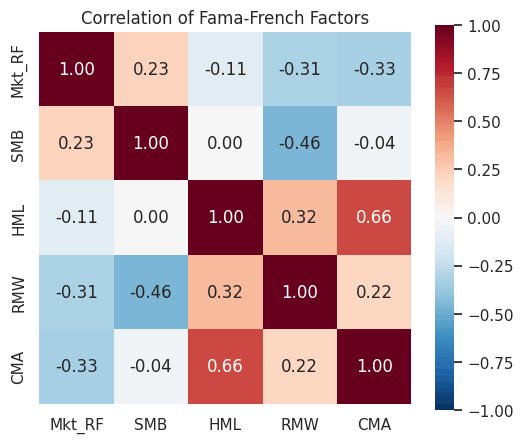

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(factor_corr, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Correlation of Fama-French Factors')
plt.show()

## Distributions and Normality

- Many statistical tests assume normality. Here we check whether the market premium is normally distributed.

### Overlaying a Normal Curve

- `stats.norm.pdf` gives the normal density. We fit it using the sample mean and standard deviation.

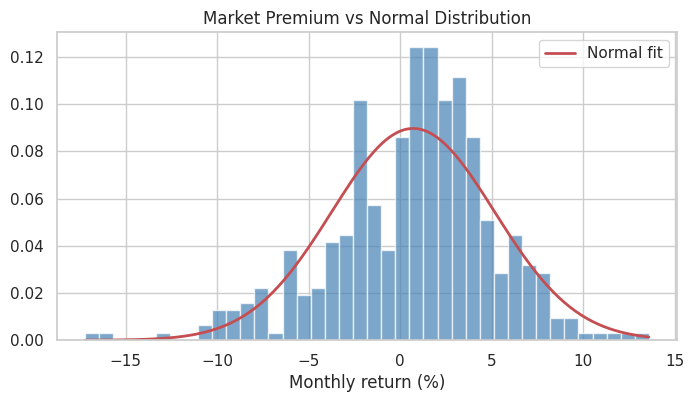

In [ ]:
mu, sigma = factors['Mkt_RF'].mean(), factors['Mkt_RF'].std()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(factors['Mkt_RF'], bins=40, density=True,
        color='steelblue', edgecolor='white', alpha=0.7)

x = np.linspace(factors['Mkt_RF'].min(), factors['Mkt_RF'].max(), 200)
ax.plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label='Normal fit')
ax.set_title('Market Premium vs Normal Distribution')
ax.set_xlabel('Monthly return (%)')
ax.legend()
plt.show()

### Testing for Normality

- The **Jarque-Bera** test uses skewness and kurtosis. A small p-value rejects normality.

In [ ]:
jb_stat, jb_pval = stats.jarque_bera(factors['Mkt_RF'])
print(f"Jarque-Bera statistic = {jb_stat:.2f}")
print(f"p-value = {jb_pval:.4f}")
if jb_pval < 0.05:
    print("=> Reject normality at the 5% level.")
else:
    print("=> Cannot reject normality at the 5% level.")

Jarque-Bera statistic = 38.05
p-value = 0.0000
=> Reject normality at the 5% level.


## Hypothesis Testing

### One-Sample t-test

- We test whether the average market premium is different from zero, that is, whether there is an equity premium.

- `stats.ttest_1samp(data, popmean)` tests whether the mean equals a hypothesized value.

In [ ]:
t_stat, p_val = stats.ttest_1samp(factors['Mkt_RF'], 0)
print(f"Mean market premium = {factors['Mkt_RF'].mean():.3f}% per month")
print(f"t-statistic = {t_stat:.3f},  p-value = {p_val:.4f}")

Mean market premium = 0.707% per month
t-statistic = 3.212,  p-value = 0.0014


### Two-Sample t-test

- The two-sample test compares the average market premium in the first and second halves of the sample.

- `stats.ttest_ind(a, b)` tests whether two groups have equal means.

In [ ]:
mid = len(factors) // 2
first_half = factors['Mkt_RF'].iloc[:mid]
second_half = factors['Mkt_RF'].iloc[mid:]

t_stat, p_val = stats.ttest_ind(first_half, second_half)
print(f"First half mean:  {first_half.mean():.3f}%")
print(f"Second half mean: {second_half.mean():.3f}%")
print(f"t-statistic = {t_stat:.3f},  p-value = {p_val:.4f}")

First half mean:  0.618%
Second half mean: 0.797%
t-statistic = -0.405,  p-value = 0.6857


## In-Class Exercise

**15-1. Descriptive Statistics:**
- Compute the mean, standard deviation, skewness, and excess kurtosis of the `HML` factor.
- Is `HML` positively or negatively skewed over this sample?

**15-2. Correlation:**
- Compute the Pearson correlation between `SMB` and `RMW`, along with its p-value.
- Is the correlation statistically significant at the 5% level?

**15-3. Equity Premium Test:**
- Run a one-sample t-test on the `RMW` (profitability) factor against a mean of zero.
- Is the average profitability premium statistically different from zero?

# Ch 16: Linear Regression with statsmodels

- `statsmodels` is the main Python library for econometric regression. It provides detailed summary tables, robust standard errors, diagnostics, and hypothesis tests.

- It has two interfaces:
  - The **formula API** (`statsmodels.formula.api`, aliased `smf`) uses R-style strings like `y ~ x1 + x2`.
  - The **arrays API** (`statsmodels.api`, aliased `sm`) takes explicit `X` and `y` arrays.

- We use the formula API for most models because it is concise and handles categorical variables automatically.

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Simple Regression: the CAPM

- The **Capital Asset Pricing Model** (CAPM) says a portfolio's excess return is explained by its sensitivity to the market:

  `R_excess = alpha + beta * Mkt_RF + error`

- A significant alpha means the portfolio earns returns that the market factor does not explain.

- We estimate the CAPM for the `HiTec` (technology) industry.

In [ ]:
# Build a regression DataFrame: one portfolio's excess return + the factors
reg_df = factors.copy()
reg_df['HiTec'] = ind_excess['HiTec']
reg_df[['HiTec', 'Mkt_RF']].head()

,HiTec,Mkt_RF
Date,,
1990-01-01,-2.04,-7.80
1990-02-01,3.47,1.11
1990-03-01,3.99,1.83
1990-04-01,-2.63,-3.36
1990-05-01,11.73,8.44


In [ ]:
capm = smf.ols('HiTec ~ Mkt_RF', data=reg_df).fit()
print(capm.summary())

                            OLS Regression Results                            
Dep. Variable:                  HiTec   R-squared:                       0.748
Model:                            OLS   Adj. R-squared:                  0.748
Method:                 Least Squares   F-statistic:                     1208.
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          9.67e-124
Time:                        05:29:07   Log-Likelihood:                -1077.7
No. Observations:                 408   AIC:                             2159.
Df Residuals:                     406   BIC:                             2167.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1116      0.171      0.654      0.5

### Reading the Summary Table

- `coef`: the estimated coefficients (`Intercept` = alpha, `Mkt_RF` = beta).
- `std err`: the standard error of each estimate.
- `t` and `P>|t|`: the t-statistic and p-value for the null hypothesis that the coefficient is zero.
- `R-squared`: the fraction of variance explained.
- `[0.025  0.975]`: the 95% confidence interval.

### Pulling Out Specific Numbers

- The fitted result stores the estimates and statistics as attributes, such as `.params`, `.rsquared`, `.tvalues`, and `.pvalues`.

In [ ]:
print(f"Alpha (monthly): {capm.params['Intercept']:.4f}")
print(f"Beta:            {capm.params['Mkt_RF']:.4f}")
print(f"R-squared:       {capm.rsquared:.4f}")
print(f"Alpha t-stat:    {capm.tvalues['Intercept']:.3f}")
print(f"Alpha p-value:   {capm.pvalues['Intercept']:.4f}")

Alpha (monthly): 0.1116
Beta:            1.3184
R-squared:       0.7485
Alpha t-stat:    0.654
Alpha p-value:   0.5134


## Multiple Regression: the 5-Factor Model

- The Fama-French 5-factor model adds size, value, profitability, and investment factors:

  `R_excess = alpha + b1*Mkt_RF + b2*SMB + b3*HML + b4*RMW + b5*CMA + error`

- Add terms to the formula with `+`.

In [ ]:
ff5 = smf.ols('HiTec ~ Mkt_RF + SMB + HML + RMW + CMA', data=reg_df).fit()
print(ff5.summary())

                            OLS Regression Results                            
Dep. Variable:                  HiTec   R-squared:                       0.860
Model:                            OLS   Adj. R-squared:                  0.859
Method:                 Least Squares   F-statistic:                     495.8
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          2.07e-169
Time:                        05:29:07   Log-Likelihood:                -957.45
No. Observations:                 408   AIC:                             1927.
Df Residuals:                     402   BIC:                             1951.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.5070      0.133      3.825      0.0

- Compare the two alphas. Adding factors usually shrinks alpha, but for `HiTec` it rises, mainly because the industry loads negatively on `HML`, `RMW`, and `CMA`, which had positive average returns over this sample.

In [ ]:
print(f"CAPM alpha:     {capm.params['Intercept']:.4f}  (R2={capm.rsquared:.3f})")
print(f"5-factor alpha: {ff5.params['Intercept']:.4f}  (R2={ff5.rsquared:.3f})")

CAPM alpha:     0.1116  (R2=0.748)
5-factor alpha: 0.5070  (R2=0.860)


## Categorical Variables and Interactions

- Use `C(variable)` to treat a column as categorical (statsmodels creates dummy variables automatically).

- Use `:` for an interaction term and `*` for "both main effects and their interaction."

- As an example, we test whether the market beta of `HiTec` was different in crisis months (2008-2009 and 2020).

In [ ]:
# Create a crisis indicator
reg_df['crisis'] = reg_df.index.year.isin([2008, 2009, 2020]).astype(int)
reg_df['crisis'].value_counts()

,count
crisis,
0,372
1,36


In [ ]:
# Mkt_RF * C(crisis) gives: Mkt_RF, the crisis dummy, and their interaction
beta_shift = smf.ols('HiTec ~ Mkt_RF * C(crisis)', data=reg_df).fit()
print(beta_shift.summary())

                            OLS Regression Results                            
Dep. Variable:                  HiTec   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     425.0
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          1.50e-124
Time:                        05:29:07   Log-Likelihood:                -1068.6
No. Observations:                 408   AIC:                             2145.
Df Residuals:                     404   BIC:                             2161.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.01

- The `Mkt_RF:C(crisis)[T.1]` coefficient is the change in beta during crisis months.
- A positive value means tech was more sensitive to the market during crises; a negative value means it was less sensitive.

## Robust Standard Errors

- OLS standard errors assume **homoskedasticity** (constant error variance). Financial data usually violates this.

- **Heteroskedasticity-robust** (White) standard errors remain valid when the error variance is not constant. Pass `cov_type='HC3'` to `.fit()`.

- The coefficients stay the same; only the standard errors (and so the t-statistics and p-values) change.

In [ ]:
ols_se = smf.ols('HiTec ~ Mkt_RF + SMB + HML', data=reg_df).fit()
rob_se = smf.ols('HiTec ~ Mkt_RF + SMB + HML', data=reg_df).fit(cov_type='HC3')

compare = pd.DataFrame({
    'coef': ols_se.params,
    'OLS_se': ols_se.bse,
    'Robust_se(HC3)': rob_se.bse,
})
compare.round(4)

,coef,OLS_se,Robust_se(HC3)
Intercept,0.2417,0.1368,0.1371
Mkt_RF,1.2447,0.0314,0.0382
SMB,0.1423,0.0456,0.0646
HML,-0.6242,0.0418,0.0557


## HAC / Newey-West Standard Errors

- Time-series regressions often have autocorrelated errors as well as heteroskedasticity.

- **HAC** (heteroskedasticity- and autocorrelation-consistent) standard errors, also called Newey-West standard errors, allow for both.

- Pass `cov_type='HAC'` and a `maxlags` value (a common rule of thumb is a few lags).

In [ ]:
hac = smf.ols('HiTec ~ Mkt_RF + SMB + HML', data=reg_df).fit(
    cov_type='HAC', cov_kwds={'maxlags': 6})

pd.DataFrame({
    'coef': hac.params,
    'OLS_se': ols_se.bse,
    'HAC_se': hac.bse,
}).round(4)

,coef,OLS_se,HAC_se
Intercept,0.2417,0.1368,0.1312
Mkt_RF,1.2447,0.0314,0.0456
SMB,0.1423,0.0456,0.0579
HML,-0.6242,0.0418,0.0770


## Clustered Standard Errors

- When observations cluster into groups (e.g., by year), errors may be correlated within clusters.

- **Clustered** standard errors account for this. Pass `cov_type='cluster'` and the grouping variable.

In [ ]:
clustered = smf.ols('HiTec ~ Mkt_RF + SMB + HML', data=reg_df).fit(
    cov_type='cluster', cov_kwds={'groups': reg_df.index.year})

pd.DataFrame({
    'coef': clustered.params,
    'OLS_se': ols_se.bse,
    'Clustered_se': clustered.bse,
}).round(4)

,coef,OLS_se,Clustered_se
Intercept,0.2417,0.1368,0.1388
Mkt_RF,1.2447,0.0314,0.0561
SMB,0.1423,0.0456,0.0518
HML,-0.6242,0.0418,0.0853


## Regression Diagnostics

### Residual Plot

- A plot of residuals against fitted values can show heteroskedasticity or nonlinearity (recall plotting from Lecture 7).

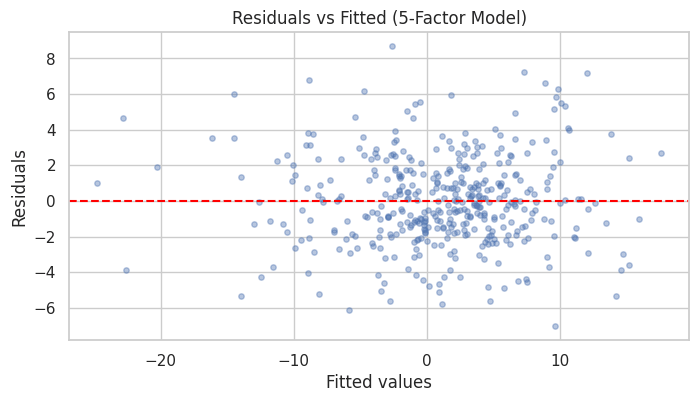

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(ff5.fittedvalues, ff5.resid, alpha=0.4, s=15)
ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Fitted values')
ax.set_ylabel('Residuals')
ax.set_title('Residuals vs Fitted (5-Factor Model)')
plt.show()

### Heteroskedasticity Test: Breusch-Pagan

- Formally test for heteroskedasticity. A small p-value indicates non-constant variance.

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_stat, bp_pval, _, _ = het_breuschpagan(ff5.resid, ff5.model.exog)
print(f"Breusch-Pagan statistic = {bp_stat:.3f}")
print(f"p-value = {bp_pval:.4f}")
if bp_pval < 0.05:
    print("=> Heteroskedasticity detected; use robust standard errors.")

Breusch-Pagan statistic = 4.855
p-value = 0.4339


### Multicollinearity: Variance Inflation Factors

- **VIF** measures how much a regressor is explained by the others. VIF > 10 signals serious multicollinearity.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(reg_df[['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA']])
vif = pd.DataFrame({
    'variable': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif.round(2)

,variable,VIF
0,const,1.00
1,Mkt_RF,1.28
2,SMB,1.32
3,HML,2.02
4,RMW,1.54
5,CMA,2.03


## Hypothesis Testing

### Testing a Single Restriction

- The summary table tests each coefficient against 0. Here we test whether the market beta equals 1.

- `.t_test()` takes a restriction string, such as `'Mkt_RF = 1'`.

In [ ]:
print(ff5.t_test('Mkt_RF = 1'))

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             1.1555      0.032      4.840      0.000       1.092       1.219


### Testing Joint Restrictions (F-test)

- An F-test checks whether the four non-market factors are jointly significant. The null hypothesis is that all four coefficients are zero.

- `.f_test()` takes the restrictions as one string, separated by commas.

In [ ]:
f_result = ff5.f_test('SMB = 0, HML = 0, RMW = 0, CMA = 0')
print(f"F-statistic = {float(f_result.fvalue):.3f}")
print(f"p-value = {float(f_result.pvalue):.4g}")

F-statistic = 80.685
p-value = 3.233e-50


## The Dummy Variable Trap

- Including a dummy for every category together with an intercept makes the regressors perfectly collinear.

- `C()` in statsmodels drops one category automatically, but dummies built by hand can cause this problem.

- The next cell creates the trap on purpose.

In [ ]:
# Manually create BOTH crisis and non-crisis dummies, then include both + intercept
reg_df['non_crisis'] = 1 - reg_df['crisis']

# crisis + non_crisis + intercept are perfectly collinear
trap = smf.ols('HiTec ~ Mkt_RF + crisis + non_crisis', data=reg_df).fit()
print(trap.summary())

                            OLS Regression Results                            
Dep. Variable:                  HiTec   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.748
Method:                 Least Squares   F-statistic:                     605.2
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          2.17e-122
Time:                        05:29:08   Log-Likelihood:                -1077.0
No. Observations:                 408   AIC:                             2160.
Df Residuals:                     405   BIC:                             2172.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.2620      0.198      1.321      0.1

/tmp/ipykernel_1690/138966126.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  trap = smf.ols('HiTec ~ Mkt_RF + crisis + non_crisis', data=reg_df).fit()


- statsmodels still reports estimates for all three terms, but it warns that the design matrix is rank-deficient (singular). The coefficients on `Intercept`, `crisis`, and `non_crisis` are not separately identified, so their individual values should not be interpreted.

- Never include a full set of dummies together with an intercept. Use `C()` and let statsmodels handle the categories.

## In-Class Exercise

**16-1. CAPM for Another Industry:**
- Estimate the CAPM (`Mkt_RF` only) for the `Utils` (utilities) industry's excess return.
- Report its beta and R-squared. Is the beta above or below 1? What does that say about utilities' market risk?

**16-2. Full 5-Factor Model:**
- Estimate the 5-factor model for the `Enrgy` (energy) industry.
- Which factors are statistically significant at the 5% level?

**16-3. Robust Standard Errors:**
- Re-estimate the 5-factor model for `Enrgy` using HAC (Newey-West) standard errors with `maxlags=6`.
- Compare the t-statistic on `Mkt_RF` to the plain-OLS version. Does the conclusion change?

**16-4. Alpha Test:**
- For the `Hlth` (healthcare) industry's 5-factor model, test whether the alpha (intercept) is statistically different from zero.
- Did healthcare deliver a significant abnormal return over this sample?

**16-5. Joint Significance:**
- For the `Shops` (retail) industry's 5-factor model, run an F-test of the joint hypothesis that `SMB`, `HML`, `RMW`, and `CMA` are all zero.
- Are the non-market factors jointly significant?

# Ch 17: Panel Data & IV with linearmodels

- Much of econometrics uses **panel data**: many entities (firms, countries, portfolios) observed over many periods.

- `statsmodels` has limited support for panel models. `linearmodels` provides fixed effects, random effects, IV/2SLS, and Fama-MacBeth estimators.

- We treat the 10 industry portfolios as a panel, with industry as the entity and month as the time period.

In [ ]:
from linearmodels import PooledOLS, PanelOLS, RandomEffects, IV2SLS, FamaMacBeth

## Building a Panel DataFrame

- `linearmodels` expects a **MultiIndex** with (entity, time).

- Our `ind_excess` is wide (one column per industry). We `melt` it to long format, then add the factors (recall reshaping and merging from Lecture 6).

In [ ]:
# Wide -> long: one row per (industry, month)
panel = ind_excess.reset_index().melt(
    id_vars='Date', var_name='industry', value_name='excess')
panel.head()

,Date,industry,excess
0,1990-01-01,NoDur,-10.04
1,1990-02-01,NoDur,-1.12
2,1990-03-01,NoDur,3.99
3,1990-04-01,NoDur,-0.86
4,1990-05-01,NoDur,8.41


In [ ]:
# Attach the factors to every row by merging on Date
factor_data = factors[['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA']].reset_index()
panel = panel.merge(factor_data, on='Date', how='left')
panel.head()

,Date,industry,excess,Mkt_RF,SMB,HML,RMW,CMA
0,1990-01-01,NoDur,-10.04,-7.80,-1.21,0.83,-1.12,1.40
1,1990-02-01,NoDur,-1.12,1.11,1.15,0.65,-0.04,-0.61
2,1990-03-01,NoDur,3.99,1.83,1.59,-2.90,1.99,-0.94
3,1990-04-01,NoDur,-0.86,-3.36,-0.35,-2.57,1.78,-1.00
4,1990-05-01,NoDur,8.41,8.44,-2.41,-3.89,1.68,-1.63


In [ ]:
# Set the (entity, time) MultiIndex that linearmodels expects
panel = panel.set_index(['industry', 'Date'])
panel.head()

excess  Mkt_RF   SMB   HML   RMW   CMA
industry Date                                              
NoDur    1990-01-01  -10.04   -7.80 -1.21  0.83 -1.12  1.40
         1990-02-01   -1.12    1.11  1.15  0.65 -0.04 -0.61
         1990-03-01    3.99    1.83  1.59 -2.90  1.99 -0.94
         1990-04-01   -0.86   -3.36 -0.35 -2.57  1.78 -1.00
         1990-05-01    8.41    8.44 -2.41 -3.89  1.68 -1.63

### Add an Entity-and-Time-Varying Regressor

- The factors are common to all industries in a given month. They vary over time but not across industries.

- To illustrate fixed effects fully, we add each industry's own lagged excess return, `lag_excess` (a momentum-style variable that varies across both dimensions).

In [ ]:
# Lag within each industry (group by the entity level of the index)
panel['lag_excess'] = panel.groupby(level='industry')['excess'].shift(1)
panel = panel.dropna()
panel.head()

excess  Mkt_RF   SMB   HML   RMW   CMA  lag_excess
industry Date                                                          
NoDur    1990-02-01   -1.12    1.11  1.15  0.65 -0.04 -0.61      -10.04
         1990-03-01    3.99    1.83  1.59 -2.90  1.99 -0.94       -1.12
         1990-04-01   -0.86   -3.36 -0.35 -2.57  1.78 -1.00        3.99
         1990-05-01    8.41    8.44 -2.41 -3.89  1.68 -1.63       -0.86
         1990-06-01    1.45   -1.09  1.31 -2.00 -0.99 -0.39        8.41

## Pooled OLS

- **Pooled OLS** ignores the panel structure. It is OLS on all rows stacked together.

- It is the baseline for the panel models below. In a `PanelOLS` formula, fixed effects are added with the `EntityEffects` and `TimeEffects` terms; `PooledOLS` includes neither.

In [ ]:
pooled = PooledOLS.from_formula(
    'excess ~ 1 + Mkt_RF + SMB + HML + lag_excess', data=panel).fit()
print(pooled)

                          PooledOLS Estimation Summary                          
Dep. Variable:                 excess   R-squared:                        0.5540
Estimator:                  PooledOLS   R-squared (Between):              0.0135
No. Observations:                4070   R-squared (Within):               0.5544
Date:                Fri, Sep 18 2026   R-squared (Overall):              0.5540
Time:                        05:29:10   Log-likelihood                 -1.11e+04
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      1262.2
Entities:                          10   P-value                           0.0000
Avg Obs:                       407.00   Distribution:                  F(4,4065)
Min Obs:                       407.00                                           
Max Obs:                       407.00   F-statistic (robust):             1262.2
                            

## Fixed Effects

### Entity (Industry) Fixed Effects

- **Entity fixed effects** absorb time-invariant differences across industries (e.g., utilities always being defensive).

- Add `EntityEffects` to the formula. We also cluster the standard errors by entity.

In [ ]:
fe_entity = PanelOLS.from_formula(
    'excess ~ 1 + Mkt_RF + SMB + HML + lag_excess + EntityEffects',
    data=panel).fit(cov_type='clustered', cluster_entity=True)
print(fe_entity)

                          PanelOLS Estimation Summary                           
Dep. Variable:                 excess   R-squared:                        0.5544
Estimator:                   PanelOLS   R-squared (Between):              0.0118
No. Observations:                4070   R-squared (Within):               0.5544
Date:                Fri, Sep 18 2026   R-squared (Overall):              0.5540
Time:                        05:29:10   Log-likelihood                 -1.11e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1261.6
Entities:                          10   P-value                           0.0000
Avg Obs:                       407.00   Distribution:                  F(4,4056)
Min Obs:                       407.00                                           
Max Obs:                       407.00   F-statistic (robust):             174.16
                            

- The factor coefficients are still identified because the factors vary over time within each industry.

### Adding Time Fixed Effects

- The next cell adds time fixed effects while keeping the common factors.

- Time effects absorb everything that is common to all industries within a month, including the factors.

In [ ]:
# Time effects fully absorb the common factors, so this cannot be estimated.
# We catch the error on purpose so you can read the message.
try:
    fe_bad = PanelOLS.from_formula(
        'excess ~ 1 + Mkt_RF + SMB + HML + EntityEffects + TimeEffects',
        data=panel).fit()
    print(fe_bad)
except Exception as e:
    print(f"{type(e).__name__}:\n")
    print(e)

AbsorbingEffectError:


The model cannot be estimated. The included effects have fully absorbed
one or more of the variables. This occurs when one or more of the dependent
variable is perfectly explained using the effects included in the model.

The following variables or variable combinations have been fully absorbed
or have become perfectly collinear after effects are removed:

          Intercept, Mkt_RF, SMB, HML
          Intercept, Mkt_RF, SMB, HML
          Intercept, Mkt_RF, SMB, HML

Set drop_absorbed=True to automatically drop absorbed variables.



- The estimation fails with an `AbsorbingEffectError`. The effect of a variable that does not vary within the fixed-effect dimension (here, across industries within a month) cannot be identified.

- In a two-way model, the time effects take the place of the factors, because they absorb all variation that is common to the industries in a given month.

### Two-Way Fixed Effects

- With both entity and time effects, we keep only the regressor that varies across both dimensions, `lag_excess`.

In [ ]:
fe_two_way = PanelOLS.from_formula(
    'excess ~ 1 + lag_excess + EntityEffects + TimeEffects',
    data=panel).fit(cov_type='clustered', cluster_entity=True)
print(fe_two_way)

                          PanelOLS Estimation Summary                           
Dep. Variable:                 excess   R-squared:                        0.0006
Estimator:                   PanelOLS   R-squared (Between):              0.0491
No. Observations:                4070   R-squared (Within):           -6.577e-05
Date:                Fri, Sep 18 2026   R-squared (Overall):          -2.702e-05
Time:                        05:29:10   Log-likelihood                  -1.1e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.1652
Entities:                          10   P-value                           0.1413
Avg Obs:                       407.00   Distribution:                  F(1,3653)
Min Obs:                       407.00                                           
Max Obs:                       407.00   F-statistic (robust):             1.7774
                            

## Random Effects

- **Random effects** (RE) treat the entity-specific term as a random draw rather than a fixed parameter.

- RE is more efficient than fixed effects (FE) if the entity effects are uncorrelated with the regressors, which is a strong assumption.

- The choice between FE and RE is traditionally guided by a **Hausman test**: if the two give very different coefficients, prefer FE.

In [ ]:
re = RandomEffects.from_formula(
    'excess ~ 1 + Mkt_RF + SMB + HML + lag_excess', data=panel).fit()
print(re)

                        RandomEffects Estimation Summary                        
Dep. Variable:                 excess   R-squared:                        0.5540
Estimator:              RandomEffects   R-squared (Between):              0.0135
No. Observations:                4070   R-squared (Within):               0.5544
Date:                Fri, Sep 18 2026   R-squared (Overall):              0.5540
Time:                        05:29:11   Log-likelihood                 -1.11e+04
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      1262.2
Entities:                          10   P-value                           0.0000
Avg Obs:                       407.00   Distribution:                  F(4,4065)
Min Obs:                       407.00                                           
Max Obs:                       407.00   F-statistic (robust):             1262.2
                            

In [ ]:
# Quick informal FE-vs-RE comparison of the key coefficient
print(f"FE  Mkt_RF coef: {fe_entity.params['Mkt_RF']:.4f}")
print(f"RE  Mkt_RF coef: {re.params['Mkt_RF']:.4f}")

FE  Mkt_RF coef: 0.9424
RE  Mkt_RF coef: 0.9424


## Instrumental Variables / 2SLS

- When a regressor is **endogenous** (correlated with the error), OLS is biased.

- **Instrumental variables** (IV) estimation, usually done by two-stage least squares (2SLS), addresses this with an instrument `z` that affects `x` but does not affect the outcome directly.

- Valid instruments are hard to find in real data, so we simulate data in which the true effect of `x` on `y` is 1.5 and compare the OLS and 2SLS estimates with that value.

In [ ]:
# Simulate endogeneity: true effect of x on y is 1.5
np.random.seed(1)
N = 2000
u = np.random.randn(N)                      # unobserved structural error
z = np.random.randn(N)                      # the instrument
x = 0.8 * z + u + np.random.randn(N) * 0.5  # x depends on z AND on u (endogenous)
y = 2.0 + 1.5 * x + 3 * u                   # u also drives y -> OLS will be biased

iv_df = pd.DataFrame({'y': y, 'x': x, 'z': z})
iv_df.head()

,y,x,z
0,9.791696,1.945773,0.489517
1,-0.360118,-0.349899,0.238796
2,-0.680531,-0.730677,-0.448112
3,-2.984499,-1.177062,-0.610795
4,3.896615,-0.466406,-2.029945


### OLS Estimate

In [ ]:
import statsmodels.formula.api as smf
ols_biased = smf.ols('y ~ x', data=iv_df).fit()
print(f"OLS estimate of x's effect: {ols_biased.params['x']:.4f}  (true = 1.5)")

OLS estimate of x's effect: 3.1055  (true = 1.5)


### 2SLS Estimate

- In `linearmodels`, the formula syntax `[x ~ z]` marks `x` as endogenous with instrument `z`.

In [ ]:
iv = IV2SLS.from_formula('y ~ 1 + [x ~ z]', data=iv_df).fit()
print(f"2SLS estimate of x's effect: {iv.params['x']:.4f}  (true = 1.5)")

2SLS estimate of x's effect: 1.4612  (true = 1.5)


- The OLS estimate is far from the true value of 1.5, while the 2SLS estimate is close to it.

## Fama-MacBeth Regression

- **Fama-MacBeth** regression is a standard method for estimating risk premia in the cross-section of asset returns. It works in two passes:

  1. **Pass 1:** for each asset, estimate its factor beta from a time-series regression.
  2. **Pass 2:** in each period, run a cross-sectional regression of returns on the betas; the slope is that period's risk premium. Then average the slopes over time.

- We apply it to the 10 industry portfolios, using the market as the only factor.

### Pass 1: Estimate Each Industry's Beta

In [ ]:
# Time-series CAPM for each industry to get its market beta
betas = {}
for ind in ind_excess.columns:
    sub = pd.DataFrame({'excess': ind_excess[ind], 'Mkt_RF': factors['Mkt_RF']})
    betas[ind] = smf.ols('excess ~ Mkt_RF', data=sub).fit().params['Mkt_RF']

beta_series = pd.Series(betas, name='beta')
beta_series.round(3)

,beta
NoDur,0.639
Durbl,1.390
Manuf,1.007
Enrgy,0.854
HiTec,1.318
Telcm,0.919
Shops,0.905
Hlth,0.713
Utils,0.435
Other,1.071


### Build a Panel with Beta as an Asset-Specific Regressor

- Each industry's beta is constant over time but varies across industries. The cross-sectional regressions in Pass 2 use this variation.

In [ ]:
# Attach each industry's beta to every one of its rows
panel_fm = ind_excess.reset_index().melt(
    id_vars='Date', var_name='industry', value_name='excess')
panel_fm['beta'] = panel_fm['industry'].map(beta_series)
panel_fm = panel_fm.set_index(['industry', 'Date'])
panel_fm.head()

excess      beta
industry Date                        
NoDur    1990-01-01  -10.04  0.639137
         1990-02-01   -1.12  0.639137
         1990-03-01    3.99  0.639137
         1990-04-01   -0.86  0.639137
         1990-05-01    8.41  0.639137

### Pass 2 by Hand

- We group by month, run a cross-sectional OLS in each month, collect the slopes, and average them (recall `groupby` from Lecture 6).

In [ ]:
slopes = []
for date, group in panel_fm.groupby(level='Date'):
    cs = smf.ols('excess ~ beta', data=group).fit()
    slopes.append(cs.params['beta'])

slopes = np.array(slopes)
fm_premium = slopes.mean()
fm_se = slopes.std(ddof=1) / np.sqrt(len(slopes))
print(f"Market risk premium (manual FM): {fm_premium:.4f}% per month")
print(f"Fama-MacBeth t-statistic: {fm_premium / fm_se:.3f}")

Market risk premium (manual FM): 0.3585% per month
Fama-MacBeth t-statistic: 1.005


### Pass 2 with linearmodels

- `FamaMacBeth` runs the monthly cross-sectional regressions and averages the slopes in one call. It takes the Pass 1 betas in `panel_fm` as given. Its `beta` estimate and t-statistic match the manual version.

In [ ]:
fm = FamaMacBeth.from_formula('excess ~ 1 + beta', data=panel_fm).fit()
print(fm)

                             FamaMacBeth Estimation Summary                            
Dep. Variable:                        excess   R-squared:                        0.0003
Estimator:                       FamaMacBeth   R-squared (Between):              0.3794
No. Observations:                       4080   R-squared (Within):               0.0000
Date:                       Fri, Sep 18 2026   R-squared (Overall):              0.0003
Time:                               05:29:14   Log-likelihood                -1.278e+04
Cov. Estimator:    Fama-MacBeth Standard Cov                                           
                                               F-statistic:                      1.3087
Entities:                                 10   P-value                           0.2527
Avg Obs:                              408.00   Distribution:                  F(1,4078)
Min Obs:                              408.00                                           
Max Obs:                        

## In-Class Exercise

**17-1. Build a Panel:**
- Using `ind_excess`, build a long-format panel with a (industry, Date) MultiIndex and a column `excess`.
- Add the `Mkt_RF` factor to each row by merging on `Date`. Print the first few rows and confirm the index names.

**17-2. Entity Fixed Effects:**
- Estimate a panel regression of `excess` on `Mkt_RF` with entity (industry) fixed effects and clustered (by entity) standard errors.
- How does the `Mkt_RF` coefficient compare to the pooled estimate?

**17-3. Pooled vs Fixed Effects:**
- Estimate the same model as 17-2 but as pooled OLS (no effects).
- Put the two `Mkt_RF` coefficients side by side. Did adding industry effects change the slope much? What does that suggest about industry-level intercept differences?

**17-4. Instrumental Variables:**
- Using the simulated `iv_df`, re-estimate the effect of `x` on `y` with 2SLS using `z` as the instrument.
- Confirm the 2SLS estimate is close to the true value of 1.5, while OLS is not.

**17-5. Fama-MacBeth:**
- Run a Fama-MacBeth regression of industry excess returns on their market `beta` using `linearmodels`.
- Report the estimated market risk premium and its t-statistic. Is the market price of risk positive over this sample?

# Ch 18: Volatility Modeling with arch

- So far we have modeled the mean of returns. In finance, the variance of returns matters as much, because it measures risk.

- Volatility (the standard deviation of returns) is not constant. Calm periods tend to be followed by calm periods, and turbulent periods by turbulent periods. This is **volatility clustering**.

- The `arch` library fits ARCH/GARCH models, the standard models for time-varying volatility.

In [ ]:
from arch import arch_model

## Volatility Clustering

- The next plot shows the monthly market premium. Big moves (up or down) tend to be followed by big moves.

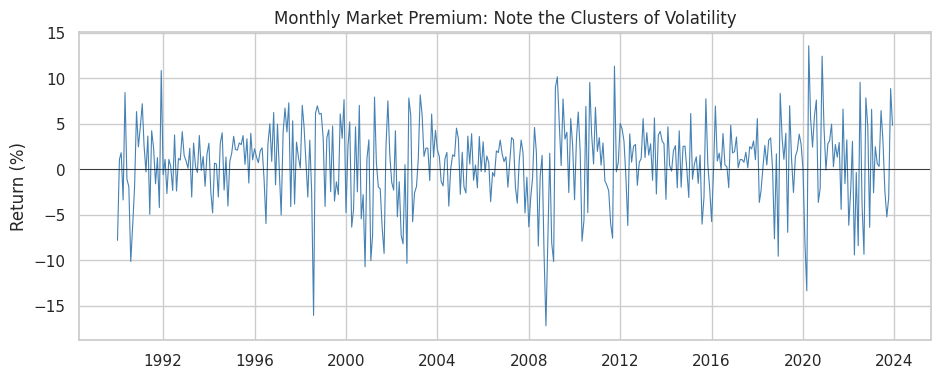

In [ ]:
mkt = factors['Mkt_RF']

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(mkt.index, mkt, linewidth=0.8, color='steelblue')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Monthly Market Premium: Note the Clusters of Volatility')
ax.set_ylabel('Return (%)')
plt.show()

### Visualizing Clustering with Squared Returns

- Squared returns proxy for variance. Plotting them makes the clusters easier to see.

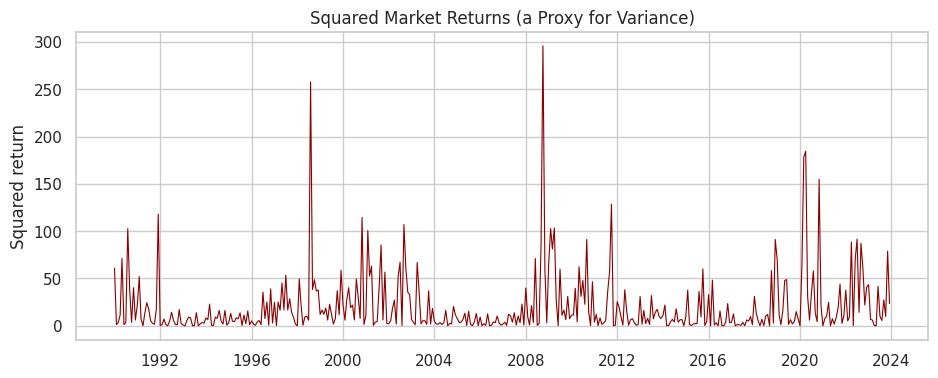

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(mkt.index, mkt**2, linewidth=0.8, color='darkred')
ax.set_title('Squared Market Returns (a Proxy for Variance)')
ax.set_ylabel('Squared return')
plt.show()

### Autocorrelation of Squared Returns

- If volatility clusters, squared returns should be autocorrelated even when returns themselves aren't.

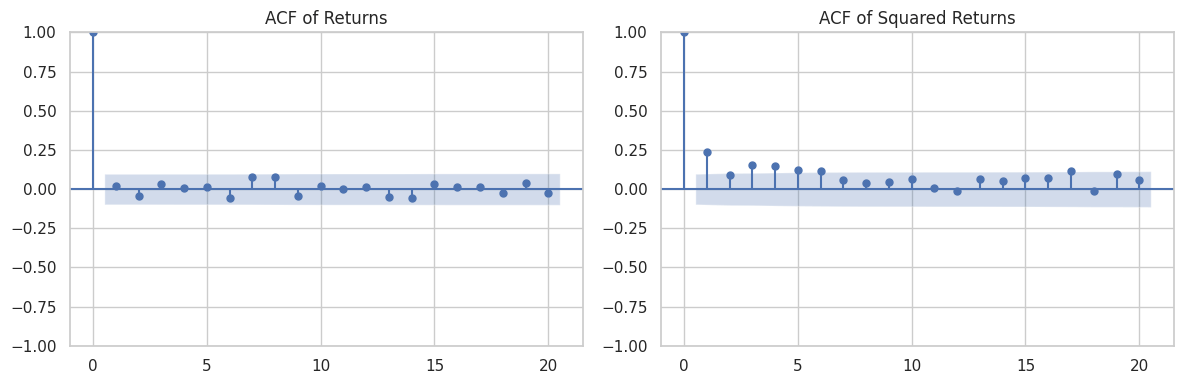

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(mkt, lags=20, ax=axes[0], title='ACF of Returns')
plot_acf(mkt**2, lags=20, ax=axes[1], title='ACF of Squared Returns')
plt.tight_layout()
plt.show()

- Returns show little autocorrelation, but squared returns are autocorrelated. This is the pattern GARCH models are designed to capture.

## The GARCH(1,1) Model

- **GARCH(1,1)** models this period's conditional variance as a function of last period's squared shock and last period's conditional variance:

  `sigma^2_t = omega + alpha * e^2_(t-1) + beta * sigma^2_(t-1)`

- The parameter alpha measures the reaction to recent shocks, and beta measures persistence.

- We specify the model with `arch_model()` and estimate it with `.fit()`.

In [ ]:
# mean='Constant' models returns as a constant plus GARCH errors
am = arch_model(mkt, mean='Constant', vol='GARCH', p=1, q=1)
res = am.fit(disp='off')
print(res.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Mkt_RF   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1158.45
Distribution:                  Normal   AIC:                           2324.90
Method:            Maximum Likelihood   BIC:                           2340.94
                                        No. Observations:                  408
Date:                Fri, Sep 18 2026   Df Residuals:                      407
Time:                        05:29:19   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.8548      0.188      4.552  5.318e-06 [  0.487,  1.22

### Interpreting the Parameters

- `omega`: the constant in the variance equation. The long-run (unconditional) variance is `omega / (1 - alpha[1] - beta[1])`, provided `alpha[1] + beta[1] < 1`.
- `alpha[1]`: sensitivity to last period's shock.
- `beta[1]`: persistence of variance.
- `alpha[1] + beta[1]`: total persistence. Values near 1 mean volatility shocks die out slowly.

In [ ]:
alpha = res.params['alpha[1]']
beta = res.params['beta[1]']
print(f"alpha (shock reaction): {alpha:.4f}")
print(f"beta  (persistence):    {beta:.4f}")
print(f"persistence (alpha+beta): {alpha + beta:.4f}")

alpha (shock reaction): 0.1933
beta  (persistence):    0.7642
persistence (alpha+beta): 0.9575


## Conditional Volatility

- The fitted model gives an estimate of volatility in each period, the **conditional volatility**.

- The plot shows when markets were calm and when they were turbulent.

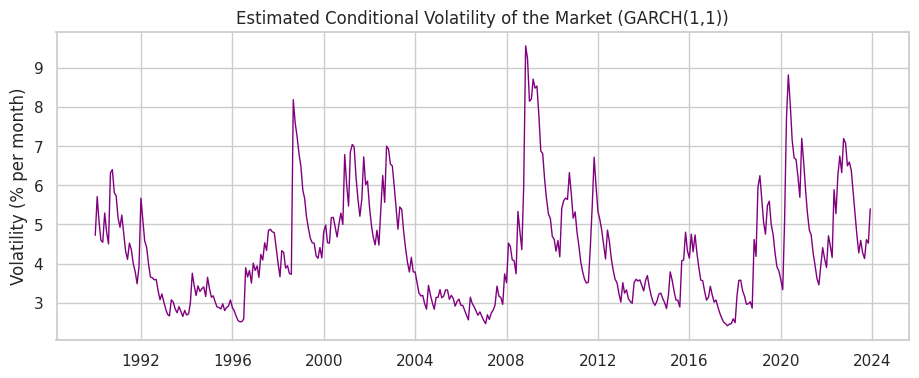

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(res.conditional_volatility.index, res.conditional_volatility,
        color='purple', linewidth=1)
ax.set_title('Estimated Conditional Volatility of the Market (GARCH(1,1))')
ax.set_ylabel('Volatility (% per month)')
plt.show()

- The spikes line up with known crises, such as 2008 and 2020.

## Volatility Forecasting

- GARCH models are often used to forecast volatility, an input to risk management and option pricing.

- `.forecast(horizon=h)` produces variance forecasts for the next `h` periods.

In [ ]:
forecast = res.forecast(horizon=6)

# The forecast holds variances; take the square root for volatility
fc_var = forecast.variance.iloc[-1]
fc_vol = np.sqrt(fc_var)
print("Volatility forecast for the next 6 months (% per month):")
print(fc_vol.round(3))

Volatility forecast for the next 6 months (% per month):
h.1    5.141
h.2    5.136
h.3    5.132
h.4    5.128
h.5    5.124
h.6    5.120
Name: 2023-12-01 00:00:00, dtype: float64


## A Note on the Mean Model

- We used `mean='Constant'`, but `arch` also supports `mean='AR'` (autoregressive mean) and different error distributions.

- For returns with fat tails, `dist='t'` (Student's t) often fits better than the default normal. We can compare with the AIC.

In [ ]:
# Compare normal vs Student-t errors using AIC (lower is better)
res_normal = arch_model(mkt, mean='Constant', vol='GARCH', p=1, q=1,
                        dist='normal').fit(disp='off')
res_t = arch_model(mkt, mean='Constant', vol='GARCH', p=1, q=1,
                   dist='t').fit(disp='off')

print(f"Normal errors AIC: {res_normal.aic:.1f}")
print(f"Student-t errors AIC: {res_t.aic:.1f}")

Normal errors AIC: 2324.9
Student-t errors AIC: 2320.2


## In-Class Exercise

**18-1. Volatility Clustering:**
- Pick the `HiTec` industry's excess return (`ind_excess['HiTec']`).
- Plot its squared returns over time. Do you see volatility clustering?

**18-2. Fit a GARCH(1,1):**
- Fit a GARCH(1,1) model with a constant mean to the `HiTec` excess return.
- Report the estimated `alpha[1]`, `beta[1]`, and their sum (persistence).

**18-3. Conditional Volatility:**
- Plot the conditional volatility from your `HiTec` GARCH model.
- Which periods show the highest estimated volatility?

**18-4. Forecast:**
- Produce a 3-month-ahead volatility forecast from your `HiTec` GARCH model.
- Convert the forecast variances to volatilities (take the square root) and print them.

# Summary

- This lecture covered four libraries:
  - `scipy.stats` for descriptive statistics and hypothesis tests
  - `statsmodels` for regression, robust inference, and diagnostics
  - `linearmodels` for panel data, IV, and Fama-MacBeth
  - `arch` for volatility modeling

- The focus was inference: coefficients, standard errors, and tests.

- Lecture 9 turns to prediction: machine learning with `scikit-learn` and an introduction to deep learning with `PyTorch`. It also returns to volatility, predicting it with machine learning and comparing the result with a GARCH(1,1) model.